In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"

## Part A — Isolation Forest fraud ranking.
Fit Isolation Forest without is_fraud on 10,000 transactions with about 1.5% fraud. Short isolation
paths score as unusual; held-back labels evaluate the ranking.


In [3]:
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")
print(fraud.head())
feature_cols = [
"amount"
,
"transaction_hour"
,
"foreign_transaction"
,
"location_mismatch"
,
"device_trust_score"
,
"velocity_last_24h"
,
"cardholder_age"
,
]
X = fraud[feature_cols]
y = fraud["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.30, random_state=42, stratify=y
)
forest = IsolationForest(n_estimators=300, contamination="auto", random_state=42, n_jobs=-1)
forest.fit(X_train) # no labels passed
anomaly_score = -forest.decision_function(X_test) # higher = more unusual

   transaction_id  amount  transaction_hour merchant_category  \
0               1   84.47                22       Electronics   
1               2  541.82                 3            Travel   
2               3  237.01                17           Grocery   
3               4  164.33                 4           Grocery   
4               5   30.53                15              Food   

   foreign_transaction  location_mismatch  device_trust_score  \
0                    0                  0                  66   
1                    1                  0                  87   
2                    0                  0                  49   
3                    0                  1                  72   
4                    0                  0                  79   

   velocity_last_24h  cardholder_age  is_fraud  
0                  3              40         0  
1                  1              64         0  
2                  1              61         0  
3                  3  

In [4]:
prevalence = y_test.mean()
ap = average_precision_score(y_test, anomaly_score)
print("fraud prevalence:"
, round(prevalence, 4))
print("ROC AUC:"
, round(roc_auc_score(y_test, anomaly_score), 4))
print("average precision:"
, round(ap, 4), " ("
, round(ap / prevalence, 1), "x prevalence)")
ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score
ranked = ranked.sort_values("anomaly_score", ascending=False)
review_budget = 100
top_k_precision = ranked.head(review_budget)["fraud_label"].mean()
print(f"fraud found in the top {review_budget}: {top_k_precision:.0%}")
print(ranked[["fraud_label"
,
"anomaly_score"
,
"amount"]].head(10))

fraud prevalence: 0.015
ROC AUC: 0.9518
average precision: 0.2249  ( 15.0 x prevalence)
fraud found in the top 100: 20%
      fraud_label  anomaly_score  amount
6394            0       0.212892  840.89
5883            0       0.168657  978.56
1623            1       0.166446  569.02
522             0       0.165520  630.67
5536            1       0.163377   28.31
9073            0       0.158442  131.05
4642            0       0.155478  351.99
645             1       0.155063  398.17
7166            0       0.154388  353.58
7698            0       0.152780   75.88


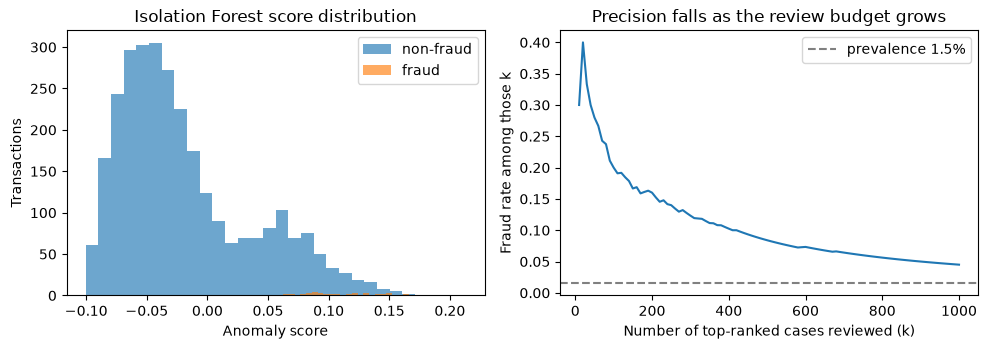

In [5]:
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 1001, 10)
precision_at_k = [hits[:k].mean() for k in k_values]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(anomaly_score[y_test.to_numpy() == 0], bins=30, alpha=0.65, label="non-fraud")
axes[0].hist(anomaly_score[y_test.to_numpy() == 1], bins=30, alpha=0.65, label="fraud")
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Isolation Forest score distribution")
axes[0].legend()
axes[1].plot(k_values, precision_at_k)
axes[1].axhline(prevalence, linestyle="--", color="grey", label=f"prevalence {prevalence:.1%}")
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among those k")
axes[1].set_title("Precision falls as the review budget grows")
axes[1].legend()
plt.tight_layout()
plt.show()

## Part B — Self-training and active learning with few labels.
Split breast-cancer rows into a query pool, validation set, and sealed test set.

In [6]:
rng = np.random.default_rng(42)
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id"
,
"diagnosis"
,
"Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()
X_dev, Xc_test, y_dev, yc_test = train_test_split(
X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)
X_pool, X_val, y_pool, y_val = train_test_split(
X_dev, y_dev, test_size=0.25, random_state=7, stratify=y_dev
)
X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)
print("pool:"
, len(X_pool), " validation:"
, len(X_val), " test:"
, len(Xc_test))
def make_model():

 return Pipeline([
("scale", StandardScaler()),
("model", LogisticRegression(max_iter=2000)),
])

pool: 319  validation: 107  test: 143


In [7]:
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1
print("labels kept:"
, int((y_partial != -1).sum()), "of"
, len(y_partial))
semi = Pipeline([
("scale", StandardScaler()),
("model", SelfTrainingClassifier(LogisticRegression(max_iter=2000), threshold=0.90)),
])
semi.fit(X_pool, y_partial)
print("self-training validation accuracy:"
,
round(accuracy_score(y_val, semi.predict(X_val)), 3))

labels kept: 89 of 319
self-training validation accuracy: 0.963


In [8]:
class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]
initial = np.concatenate([rng.choice(class0, 20, replace=False),
                          rng.choice(class1, 20, replace=False)])

active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())
rng_random = np.random.default_rng(123)

query_batch, rounds = 15, 8
label_counts, active_scores, random_scores = [], [], []

for round_no in range(rounds):
    active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
    active = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
    random_model = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])

    label_counts.append(len(active_labeled))
    active_scores.append(accuracy_score(y_val, active.predict(X_val)))
    random_scores.append(accuracy_score(y_val, random_model.predict(X_val)))
    print(f"round {round_no + 1}: labels={label_counts[-1]:3d} "
          f"uncertainty={active_scores[-1]:.3f} random={random_scores[-1]:.3f}")

    if round_no == rounds - 1:
        break

    # Active learning: pick the 15 points the model is least sure about
    unlabeled = np.array([i for i in range(len(X_pool)) if i not in active_labeled])
    uncertainty = np.abs(active.predict_proba(X_pool.iloc[unlabeled])[:, 1] - 0.5)
    active_labeled.update(unlabeled[np.argsort(uncertainty)[:query_batch]].tolist())

    # Baseline: pick 15 points at random
    unlabeled = np.array([i for i in range(len(X_pool)) if i not in random_labeled])
    random_labeled.update(rng_random.choice(unlabeled, query_batch, replace=False).tolist())

round 1: labels= 40 uncertainty=0.944 random=0.944
round 2: labels= 55 uncertainty=0.925 random=0.953
round 3: labels= 70 uncertainty=0.981 random=0.963
round 4: labels= 85 uncertainty=0.953 random=0.963
round 5: labels=100 uncertainty=0.953 random=0.953
round 6: labels=115 uncertainty=0.953 random=0.953
round 7: labels=130 uncertainty=0.953 random=0.963
round 8: labels=145 uncertainty=0.953 random=0.963


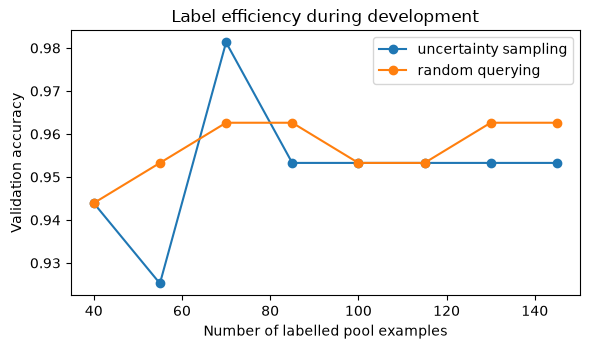

In [9]:
plt.figure(figsize=(6, 3.6))
plt.plot(label_counts, active_scores, marker="o", label="uncertainty sampling")
plt.plot(label_counts, random_scores, marker="o", label="random querying")
plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label efficiency during development")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
active_final = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
random_final = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])
print("final test accuracy, uncertainty sampling:"
,
round(accuracy_score(yc_test, active_final.predict(Xc_test)), 3))
print("final test accuracy, random querying: "
,
round(accuracy_score(yc_test, random_final.predict(Xc_test)), 3))


final test accuracy, uncertainty sampling: 0.972
final test accuracy, random querying:  0.972


## Try it myself 


In [11]:
# Try it yourself (1): precision at different review budgets
for budget in [50, 100, 300]:
    top = ranked.head(budget)
    caught = int(top["fraud_label"].sum())
    precision = top["fraud_label"].mean()
    print(f"budget={budget:3d}: fraud caught={caught:3d}, "
          f"precision={precision:.1%}, lift={precision / prevalence:.1f}x prevalence")

print("total fraud cases in test set:", int(ranked["fraud_label"].sum()))

budget= 50: fraud caught= 14, precision=28.0%, lift=18.7x prevalence
budget=100: fraud caught= 20, precision=20.0%, lift=13.3x prevalence
budget=300: fraud caught= 37, precision=12.3%, lift=8.2x prevalence
total fraud cases in test set: 45


Start with 20 labels per class (40 total):
  round 1: labels= 40  uncertainty=0.925  random=0.925
  round 2: labels= 55  uncertainty=0.953  random=0.944
  round 3: labels= 70  uncertainty=0.972  random=0.944
  round 4: labels= 85  uncertainty=0.953  random=0.935
  round 5: labels=100  uncertainty=0.963  random=0.953
  round 6: labels=115  uncertainty=0.963  random=0.953
  round 7: labels=130  uncertainty=0.963  random=0.963
  round 8: labels=145  uncertainty=0.963  random=0.963
Start with 10 labels per class (20 total):
  round 1: labels= 20  uncertainty=0.935  random=0.935
  round 2: labels= 35  uncertainty=0.944  random=0.944
  round 3: labels= 50  uncertainty=0.963  random=0.963
  round 4: labels= 65  uncertainty=0.953  random=0.953
  round 5: labels= 80  uncertainty=0.953  random=0.963
  round 6: labels= 95  uncertainty=0.953  random=0.944
  round 7: labels=110  uncertainty=0.953  random=0.953
  round 8: labels=125  uncertainty=0.953  random=0.944


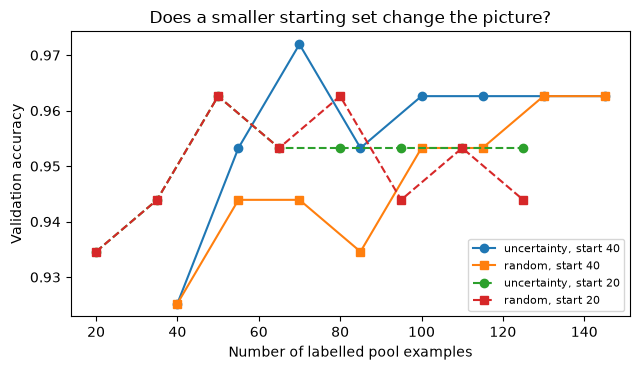

In [12]:
# Try it yourself (2): uncertainty sampling vs random, starting from 10 vs 20 labels per class
def run_policies(n_per_class, query_batch=15, rounds=8, seed=42):
    rng_start = np.random.default_rng(seed)
    class0 = np.where(y_pool == 0)[0]
    class1 = np.where(y_pool == 1)[0]
    initial = np.concatenate([rng_start.choice(class0, n_per_class, replace=False),
                              rng_start.choice(class1, n_per_class, replace=False)])
    active_labeled = set(initial.tolist())
    random_labeled = set(initial.tolist())
    rng_random = np.random.default_rng(123)

    counts, active_acc, random_acc = [], [], []
    for round_no in range(rounds):
        active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
        active = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
        random_model = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])

        counts.append(len(active_labeled))
        active_acc.append(accuracy_score(y_val, active.predict(X_val)))
        random_acc.append(accuracy_score(y_val, random_model.predict(X_val)))
        print(f"  round {round_no + 1}: labels={counts[-1]:3d}  "
              f"uncertainty={active_acc[-1]:.3f}  random={random_acc[-1]:.3f}")
        if round_no == rounds - 1:
            break

        unlabeled = np.array([i for i in range(len(X_pool)) if i not in active_labeled])
        uncertainty = np.abs(active.predict_proba(X_pool.iloc[unlabeled])[:, 1] - 0.5)
        active_labeled.update(unlabeled[np.argsort(uncertainty)[:query_batch]].tolist())

        unlabeled = np.array([i for i in range(len(X_pool)) if i not in random_labeled])
        random_labeled.update(rng_random.choice(unlabeled, query_batch, replace=False).tolist())

    return counts, active_acc, random_acc

results = {}
for n in [20, 10]:
    print(f"Start with {n} labels per class ({2 * n} total):")
    results[n] = run_policies(n)

plt.figure(figsize=(6.5, 3.8))
for n, style in [(20, "-"), (10, "--")]:
    counts, active_acc, random_acc = results[n]
    plt.plot(counts, active_acc, marker="o", linestyle=style, label=f"uncertainty, start {2 * n}")
    plt.plot(counts, random_acc, marker="s", linestyle=style, label=f"random, start {2 * n}")
plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Does a smaller starting set change the picture?")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Starting with 20 labels per class, uncertainty sampling beat random querying in the middle rounds and peaked at 0.972 with 70 labels, compared with 0.944 for random. Both reached 0.963 once 130 labels were used. Starting with only 10 labels per class, the two policies gave the same accuracy for the first four rounds, then went back and forth with no clear winner, ending at 0.953 for uncertainty and 0.944 for random.
Therefore a smaller starting set did not make uncertainty sampling more useful here. This is because when the first model is trained on only 20 examples, its probability estimates are unreliable, so the cases it marks as “most uncertain” are not truly the most informative ones. In addition, each difference of about 0.009 is roughly one validation case, so most of these gaps are within normal variation. Therefore on this dataset both policies reach similar accuracy, and a fixed random seed is not enough to claim one is better. Repeating the experiment with several seeds would give a fairer comparison.
